<a href="https://colab.research.google.com/github/ilsafaisal15/Computer-Vision-Object-Detector-and-Frame-by-Frame-Segmenter-Pipeline/blob/main/Task_3_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install ultralytics

In [ ]:
import os, time, math, shutil, subprocess
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import Video, display

os.makedirs("outputs", exist_ok=True)
print("OpenCV", cv2.__version__)

OpenCV 4.14.0


In [ ]:
USE_UPLOAD = False        # True -> upload your own video (YOLO works best on real footage: people, cars, etc.)
W, H, FPS, N_FRAMES = 640, 480, 30, 150

def make_synthetic_video(path, n_frames=N_FRAMES, seed=0):
    """Moving circles / rectangles / triangles on a noisy background. Returns ground truth per frame."""
    rng = np.random.default_rng(seed)
    objs = []
    for i in range(7):
        kind = ["circle", "rectangle", "triangle"][i % 3]
        objs.append(dict(kind=kind,
                         p=rng.uniform([80, 80], [W-80, H-80]),
                         v=rng.uniform(-4, 4, 2) + np.array([1.5, 1.0]),
                         s=int(rng.integers(22, 34)),
                         color=tuple(int(x) for x in rng.integers(20, 110, 3))))
    base = np.full((H, W, 3), 215, np.uint8)
    out = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
    gt = []
    for f in range(n_frames):
        frame = base.copy()
        frame_gt = []
        for o in objs:
            o["p"] = o["p"] + o["v"]
            for ax, lim in ((0, W), (1, H)):
                if o["p"][ax] < o["s"] + 5 or o["p"][ax] > lim - o["s"] - 5:
                    o["v"][ax] *= -1
                    o["p"][ax] = np.clip(o["p"][ax], o["s"] + 5, lim - o["s"] - 5)
            cx, cy = o["p"]; s = o["s"]
            if o["kind"] == "circle":
                cv2.circle(frame, (int(cx), int(cy)), s, o["color"], -1)
                c = (cx, cy)
            elif o["kind"] == "rectangle":
                cv2.rectangle(frame, (int(cx-s), int(cy-s*0.7)), (int(cx+s), int(cy+s*0.7)), o["color"], -1)
                c = (cx, cy)
            else:
                pts = np.array([[cx, cy-s], [cx-s, cy+s*0.8], [cx+s, cy+s*0.8]], np.int32)
                cv2.fillPoly(frame, [pts], o["color"])
                c = (cx, (cy-s + 2*(cy+s*0.8))/3)
            frame_gt.append((o["kind"], float(c[0]), float(c[1])))
        noise = rng.normal(0, 6, frame.shape)
        frame = np.clip(frame.astype(np.float32) + noise, 0, 255).astype(np.uint8)
        out.write(frame)
        gt.append(frame_gt)
    out.release()
    return gt

if USE_UPLOAD:
    from google.colab import files
    up = files.upload()
    VIDEO_PATH = list(up.keys())[0]
    GT = None
else:
    VIDEO_PATH = "synthetic.mp4"
    GT = make_synthetic_video(VIDEO_PATH)

cap = cv2.VideoCapture(VIDEO_PATH)
print("Video:", VIDEO_PATH, "| frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
      "| size:", int(cap.get(3)), "x", int(cap.get(4)), "| fps:", cap.get(cv2.CAP_PROP_FPS))
cap.release()

Video: synthetic.mp4 | frames: 150 | size: 640 x 480 | fps: 30.0


In [ ]:
PARAMS = dict(GAUSS_K=7, BLOCK=51, C=10, MIN_AREA=600, MAX_AREA=20000, MORPH_K=5)

CLASS_COLORS = {"circle": (0, 160, 0), "rectangle": (200, 80, 0), "triangle": (0, 0, 220), "polygon": (150, 0, 150)}

def classify_shape(cnt):
    peri = cv2.arcLength(cnt, True)
    area = cv2.contourArea(cnt)
    approx = cv2.approxPolyDP(cnt, 0.04 * peri, True)
    circ = 4 * math.pi * area / (peri * peri + 1e-9)
    n = len(approx)
    if n == 3: return "triangle"
    if n == 4: return "rectangle"
    if circ > 0.80: return "circle"
    return "polygon"

class CentroidTracker:
    """Nearest-centroid tracker giving each object a persistent ID."""
    def __init__(self, max_dist=60, max_missed=8):
        self.next_id, self.objs, self.max_dist, self.max_missed = 0, {}, max_dist, max_missed
    def update(self, dets):
        ids = [None] * len(dets)
        used = set()
        for i, d in enumerate(dets):
            best, bd = None, self.max_dist
            for oid, o in self.objs.items():
                if oid in used: continue
                dist = math.hypot(d["cx"] - o["c"][0], d["cy"] - o["c"][1])
                if dist < bd: best, bd = oid, dist
            if best is not None:
                used.add(best); ids[i] = best
                self.objs[best].update(c=(d["cx"], d["cy"]), missed=0)
        for i, d in enumerate(dets):
            if ids[i] is None:
                self.objs[self.next_id] = dict(c=(d["cx"], d["cy"]), missed=0)
                ids[i] = self.next_id; self.next_id += 1
        for oid in list(self.objs):
            if oid not in used and oid not in ids:
                self.objs[oid]["missed"] += 1
                if self.objs[oid]["missed"] > self.max_missed: del self.objs[oid]
        return ids

def draw_count_overlay(img, counts, extra=""):
    text = " | ".join(f"{k}: {v}" for k, v in sorted(counts.items())) or "no targets"
    text = f"{text} | total: {sum(counts.values())}{extra}"
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
    cv2.rectangle(img, (0, 0), (tw + 20, th + 20), (0, 0, 0), -1)
    cv2.putText(img, text, (10, th + 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)

def classical_process(frame, tracker, p=PARAMS):
    t = {}
    t0 = time.perf_counter()
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (p["GAUSS_K"], p["GAUSS_K"]), 0);                    t["blur"] = time.perf_counter()
    thr = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY_INV, p["BLOCK"], p["C"]);              t["thresh"] = time.perf_counter()
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (p["MORPH_K"], p["MORPH_K"]))
    thr = cv2.morphologyEx(thr, cv2.MORPH_CLOSE, k, iterations=2);                      t["morph"] = time.perf_counter()
    cnts, _ = cv2.findContours(thr, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE);        t["contours"] = time.perf_counter()

    dets = []
    for c in cnts:
        a = cv2.contourArea(c)
        if p["MIN_AREA"] <= a <= p["MAX_AREA"]:                  # pixel-bound filter
            m = cv2.moments(c)
            if m["m00"] == 0: continue
            dets.append(dict(cnt=c, area=a, cls=classify_shape(c),
                             cx=m["m10"] / m["m00"], cy=m["m01"] / m["m00"], box=cv2.boundingRect(c)))
    ids = tracker.update(dets);                                                         t["track"] = time.perf_counter()

    out = frame.copy()
    counts = {}
    for d, oid in zip(dets, ids):
        counts[d["cls"]] = counts.get(d["cls"], 0) + 1
        col = CLASS_COLORS[d["cls"]]
        cv2.drawContours(out, [d["cnt"]], -1, col, 2)
        x, y, w, h = d["box"]
        cv2.putText(out, f"{d['cls']} #{oid}", (x, max(y - 6, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 2, cv2.LINE_AA)
    draw_count_overlay(out, counts);                                                    t["draw"] = time.perf_counter()

    stages, prev = {}, t0
    for name in ["blur", "thresh", "morph", "contours", "track", "draw"]:
        stages[f"{name}_ms"] = (t[name] - prev) * 1000; prev = t[name]
    total_ms = (prev - t0) * 1000
    dets_out = [dict(cls=d["cls"], cx=d["cx"], cy=d["cy"], area=d["area"]) for d in dets]
    return out, dict(counts=counts, n_det=len(dets), total_ms=total_ms, **stages), dets_out, thr

In [ ]:
def to_h264(src, dst):
    """Re-encode so the video plays inside the notebook."""
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src, "-vcodec", "libx264", "-pix_fmt", "yuv420p", dst])

def run_video(path, process_fn, out_path):
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    w, h = int(cap.get(3)), int(cap.get(4))
    writer = cv2.VideoWriter("tmp_" + out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    metrics, all_dets, debug_frames = [], [], []
    idx = 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        wall0 = time.perf_counter()
        out, m, dets, extra = process_fn(frame)
        m["wall_ms"] = (time.perf_counter() - wall0) * 1000
        m["fps_inst"] = 1000.0 / m["wall_ms"]
        m["frame"] = idx
        writer.write(out)
        metrics.append(m); all_dets.append(dets)
        if idx in (30, 90): debug_frames.append((frame, out, extra))
        idx += 1
    cap.release(); writer.release()
    to_h264("tmp_" + out_path, "outputs/" + out_path)
    os.remove("tmp_" + out_path)
    return pd.DataFrame(metrics), all_dets, debug_frames

tracker = CentroidTracker()
df_cv, dets_cv, dbg_cv = run_video(VIDEO_PATH, lambda f: classical_process(f, tracker), "classical_annotated.mp4")
print(f"Classical pipeline: {len(df_cv)} frames | mean latency {df_cv.wall_ms.mean():.2f} ms | mean FPS {1000/df_cv.wall_ms.mean():.1f}")
print("Unique track IDs created:", tracker.next_id)

Classical pipeline: 150 frames | mean latency 15.20 ms | mean FPS 65.8
Unique track IDs created: 9


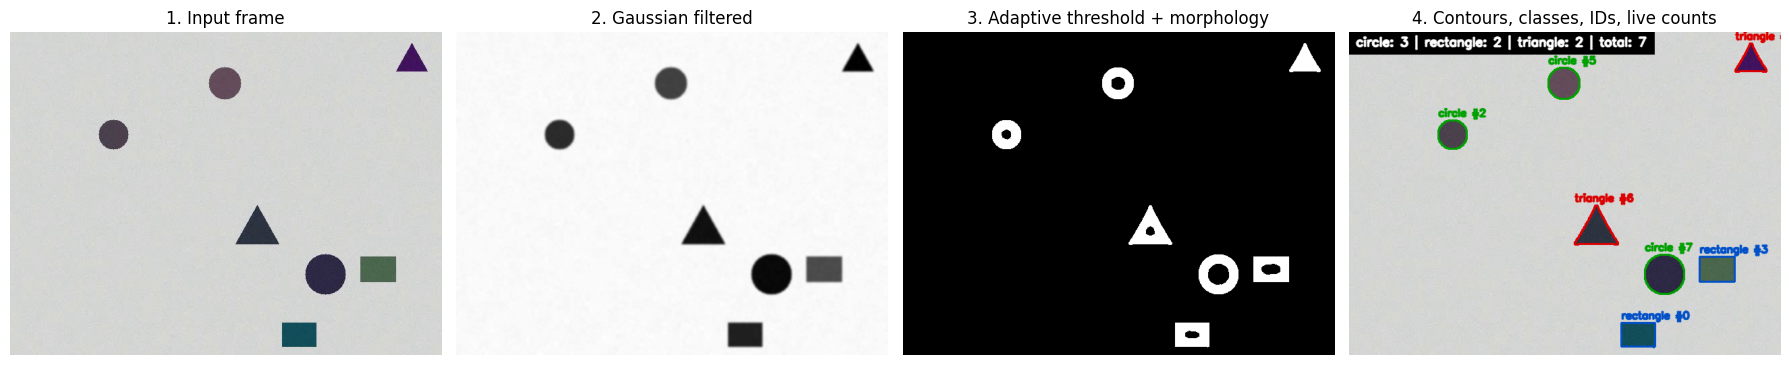

In [ ]:
# Intermediate stages for one frame (good figure for the whitepaper)
frame, out, thr = dbg_cv[0]
blur = cv2.GaussianBlur(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (PARAMS["GAUSS_K"],)*2, 0)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))
ax[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); ax[0].set_title("1. Input frame")
ax[1].imshow(blur, cmap="gray");                       ax[1].set_title("2. Gaussian filtered")
ax[2].imshow(thr, cmap="gray");                        ax[2].set_title("3. Adaptive threshold + morphology")
ax[3].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB));    ax[3].set_title("4. Contours, classes, IDs, live counts")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("outputs/pipeline_stages.png", dpi=150); plt.show()
display(Video("outputs/classical_annotated.mp4", embed=True, width=640))

In [ ]:
def evaluate(dets_per_frame, gt, dist_thr=25):
    tp = fp = fn = 0
    rows = []
    for f, (dets, truth) in enumerate(zip(dets_per_frame, gt)):
        used, ftp = set(), 0
        for d in dets:
            best, bd = None, dist_thr
            for j, (k, x, y) in enumerate(truth):
                if j in used or k != d["cls"]: continue
                dist = math.hypot(d["cx"] - x, d["cy"] - y)
                if dist < bd: best, bd = j, dist
            if best is not None: used.add(best); ftp += 1
        ffp, ffn = len(dets) - ftp, len(truth) - ftp
        tp += ftp; fp += ffp; fn += ffn
        rows.append(dict(frame=f, tp=ftp, fp=ffp, fn=ffn, gt_count=len(truth), det_count=len(dets)))
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return prec, rec, 2 * prec * rec / max(prec + rec, 1e-9), pd.DataFrame(rows)

if GT is not None:
    prec, rec, f1, df_eval = evaluate(dets_cv, GT)
    mae = (df_eval.det_count - df_eval.gt_count).abs().mean()
    print(f"Precision {prec:.3f} | Recall {rec:.3f} | F1 {f1:.3f} | Count MAE per frame {mae:.2f}")
    df_cv = df_cv.merge(df_eval, on="frame")
else:
    print("No ground truth for uploaded video: report latency/FPS and qualitative results instead.")

Precision 0.938 | Recall 0.876 | F1 0.906 | Count MAE per frame 0.46


In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8n-seg.pt")
import torch
print("Device:", "GPU" if torch.cuda.is_available() else "CPU  (Runtime > Change runtime type > T4 GPU for faster inference)")

def yolo_process(frame):
    r = model(frame, verbose=False, conf=0.35)[0]
    out = r.plot()                                          # boxes + segmentation masks
    counts = {}
    confs = []
    dets = []
    for b in r.boxes:
        name = model.names[int(b.cls)]
        counts[name] = counts.get(name, 0) + 1
        confs.append(float(b.conf))
        x1, y1, x2, y2 = b.xyxy[0].tolist()
        dets.append(dict(cls=name, cx=(x1+x2)/2, cy=(y1+y2)/2, area=(x2-x1)*(y2-y1)))
    draw_count_overlay(out, counts)
    m = dict(counts=counts, n_det=len(dets), mean_conf=float(np.mean(confs)) if confs else np.nan,
             pre_ms=r.speed["preprocess"], inf_ms=r.speed["inference"], post_ms=r.speed["postprocess"],
             total_ms=sum(r.speed.values()))
    return out, m, dets, None

_ = yolo_process(np.zeros((H, W, 3), np.uint8))             # warm-up (first call is slow)
df_yolo, dets_yolo, dbg_yolo = run_video(VIDEO_PATH, yolo_process, "yolo_annotated.mp4")
print(f"YOLO pipeline: {len(df_yolo)} frames | mean latency {df_yolo.wall_ms.mean():.2f} ms | mean FPS {1000/df_yolo.wall_ms.mean():.1f}")
display(Video("outputs/yolo_annotated.mp4", embed=True, width=640))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: GPU
YOLO pipeline: 150 frames | mean latency 24.45 ms | mean FPS 40.9


,Pipeline,Mean latency (ms),Median latency (ms),P95 latency (ms),Mean FPS,Mean detections/frame
0,Classical OpenCV,15.20,12.77,35.57,65.77,6.54
1,YOLOv8n-seg,24.45,14.71,20.90,40.90,0.35


,mean ms per stage
blur_ms,1.714
thresh_ms,7.632
morph_ms,0.899
contours_ms,0.317
track_ms,0.298
draw_ms,4.280


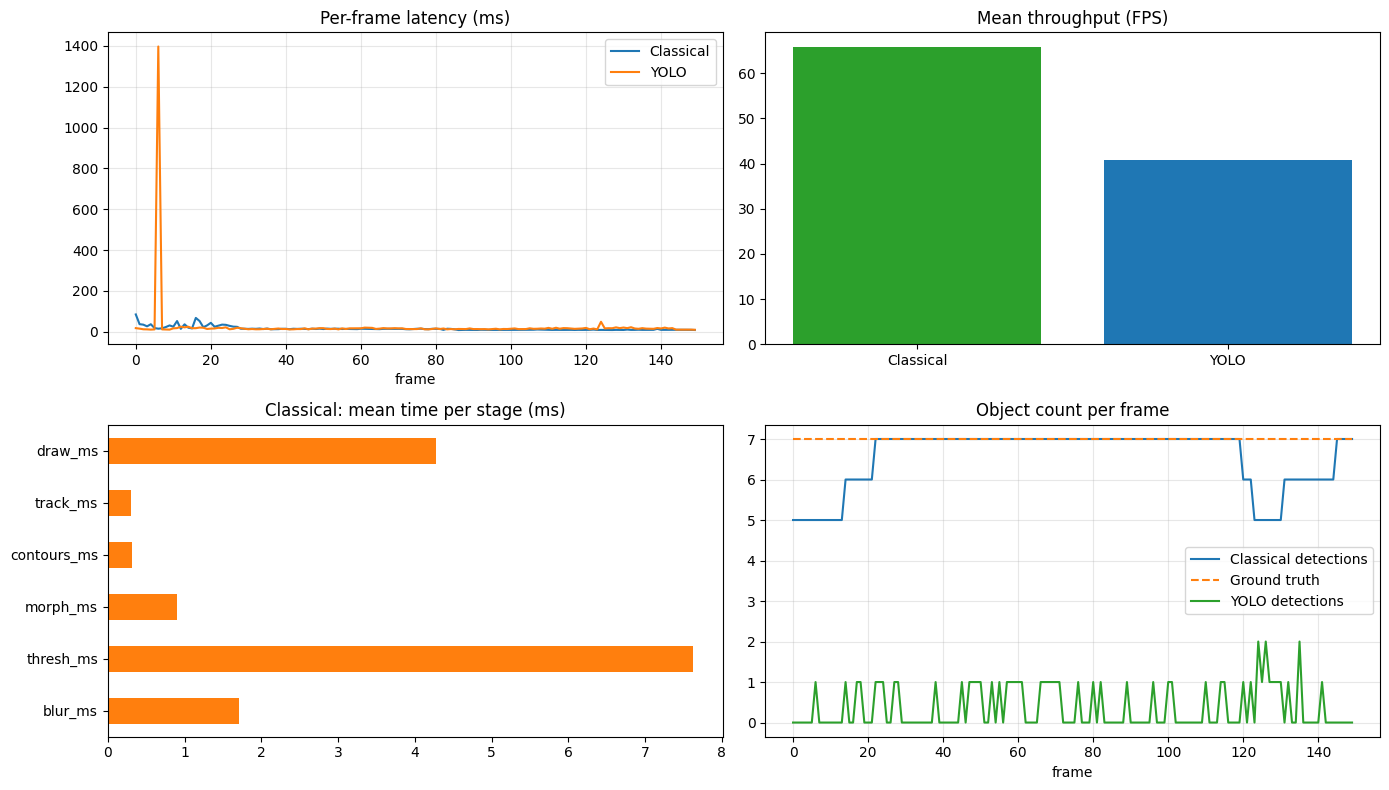

In [ ]:
df_cv.drop(columns=["counts"]).to_csv("outputs/metrics_classical.csv", index=False)
df_yolo.drop(columns=["counts"]).to_csv("outputs/metrics_yolo.csv", index=False)

summary = pd.DataFrame({
    "Pipeline": ["Classical OpenCV", "YOLOv8n-seg"],
    "Mean latency (ms)": [df_cv.wall_ms.mean(), df_yolo.wall_ms.mean()],
    "Median latency (ms)": [df_cv.wall_ms.median(), df_yolo.wall_ms.median()],
    "P95 latency (ms)": [df_cv.wall_ms.quantile(.95), df_yolo.wall_ms.quantile(.95)],
    "Mean FPS": [1000 / df_cv.wall_ms.mean(), 1000 / df_yolo.wall_ms.mean()],
    "Mean detections/frame": [df_cv.n_det.mean(), df_yolo.n_det.mean()],
}).round(2)
summary.to_csv("outputs/summary_table.csv", index=False)
display(summary)

# Classical per-stage breakdown
stage_cols = ["blur_ms", "thresh_ms", "morph_ms", "contours_ms", "track_ms", "draw_ms"]
display(df_cv[stage_cols].mean().round(3).to_frame("mean ms per stage"))

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0,0].plot(df_cv.frame, df_cv.wall_ms, label="Classical"); ax[0,0].plot(df_yolo.frame, df_yolo.wall_ms, label="YOLO")
ax[0,0].set_title("Per-frame latency (ms)"); ax[0,0].set_xlabel("frame"); ax[0,0].legend(); ax[0,0].grid(alpha=.3)

ax[0,1].bar(["Classical", "YOLO"], summary["Mean FPS"], color=["tab:green", "tab:blue"])
ax[0,1].set_title("Mean throughput (FPS)")

df_cv[stage_cols].mean().plot.barh(ax=ax[1,0], color="tab:orange"); ax[1,0].set_title("Classical: mean time per stage (ms)")

ax[1,1].plot(df_cv.frame, df_cv.n_det, label="Classical detections")
if GT is not None: ax[1,1].plot(df_cv.frame, df_cv.gt_count, "--", label="Ground truth")
ax[1,1].plot(df_yolo.frame, df_yolo.n_det, label="YOLO detections")
ax[1,1].set_title("Object count per frame"); ax[1,1].set_xlabel("frame"); ax[1,1].legend(); ax[1,1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("outputs/metrics_overview.png", dpi=150); plt.show()

In [ ]:
# Parameter sensitivity study (great for the whitepaper's analysis section)
if GT is not None:
    rows = []
    for block in [21, 41, 51, 81]:
        for gk in [3, 7, 11]:
            p = dict(PARAMS, BLOCK=block, GAUSS_K=gk)
            trk = CentroidTracker()
            cap = cv2.VideoCapture(VIDEO_PATH); dets_all, lat = [], []
            while True:
                ok, fr = cap.read()
                if not ok: break
                _, m, d, _ = classical_process(fr, trk, p); dets_all.append(d); lat.append(m["total_ms"])
            cap.release()
            pr, rc, f1, _ = evaluate(dets_all, GT)
            rows.append(dict(block_size=block, gaussian_k=gk, precision=pr, recall=rc, f1=f1, mean_ms=np.mean(lat)))
    sens = pd.DataFrame(rows).round(3)
    sens.to_csv("outputs/parameter_sensitivity.csv", index=False)
    display(sens.sort_values("f1", ascending=False))

,block_size,gaussian_k,precision,recall,f1,mean_ms
10,81,7,0.939,0.877,0.907,16.859
7,51,7,0.938,0.876,0.906,8.870
11,81,11,0.937,0.877,0.906,16.916
5,41,11,0.935,0.875,0.904,8.529
8,51,11,0.934,0.873,0.903,13.099
4,41,7,0.936,0.873,0.903,21.319
2,21,11,0.934,0.871,0.901,7.065
0,21,3,0.935,0.870,0.901,7.427
3,41,3,0.935,0.870,0.901,14.729
6,51,3,0.934,0.870,0.900,8.363


In [ ]:
shutil.make_archive("cv_pipeline_results", "zip", "outputs")
try:
    from google.colab import files
    files.download("cv_pipeline_results.zip")
except ImportError:
    print("Results are in ./outputs and cv_pipeline_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>